In [37]:
import numpy as np
from PIL import Image
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision
import torchvision.transforms as transforms
from torchvision import models
from torchvision.models import ResNet18_Weights
from torchvision.transforms import v2

from skimage import io, transform
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

import matplotlib.pyplot as plt

import os

import cv2

import copy

In [38]:
device = "mps" if torch.backends.mps.is_available() else "cpu"
img_size = 224
data_dir = 'images/'
labels = ['aurora']
batch_size = 32
epochs = 100

# Loading the data

In [39]:
data = pd.read_csv('final_final_labels.csv')
data['img'] = data['img'].map(lambda x: os.path.join(data_dir, x))

data = data.drop(['overcast', 'clear', 'cloudy', 'Unnamed: 0.1', 'Unnamed: 0'], axis=1)
data['datetime'] = pd.to_datetime(
    data['img'].str.extract(
        r'(\d{4}-\d{2}-\d{2}T\d{2}\.\d{2}\.\d{2}\.\d{3})'
    )[0],
    format='%Y-%m-%dT%H.%M.%S.%f'
)


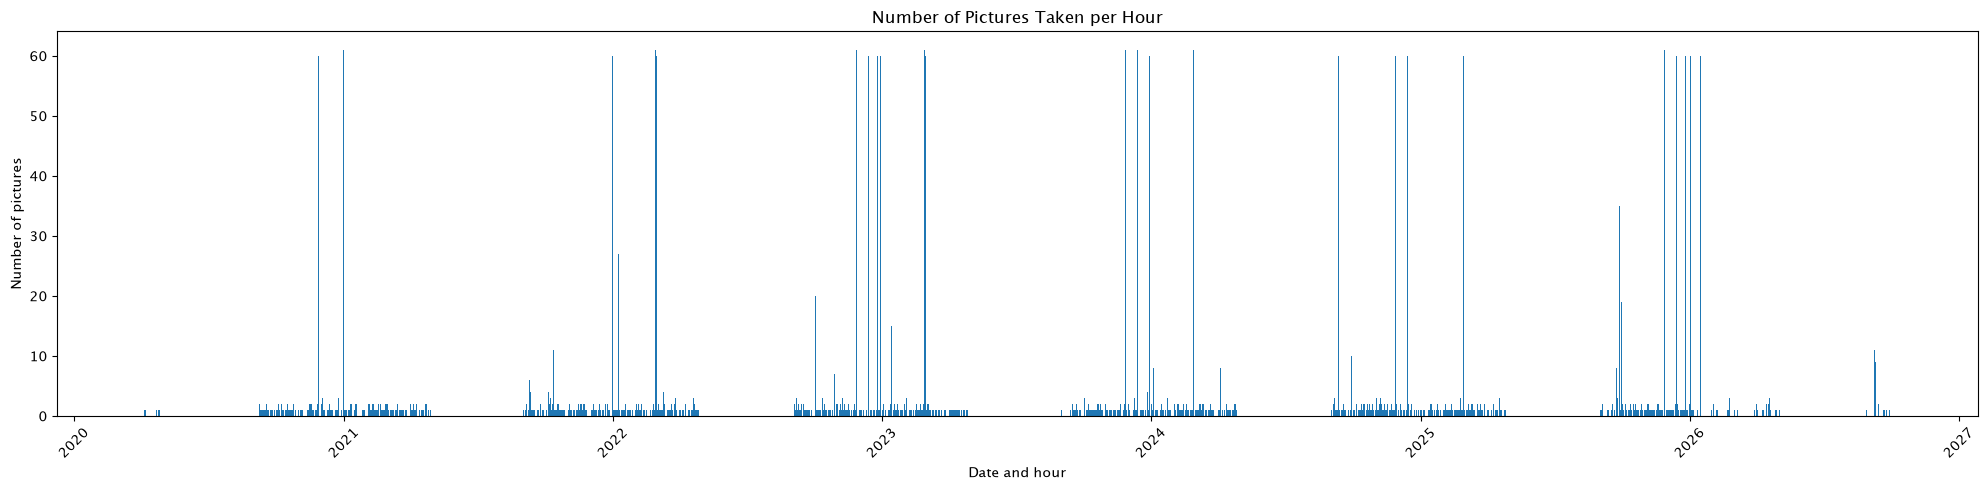

In [40]:
hourly_counts = (
    data.groupby(data['datetime'].dt.floor('h'))
        .size()
)

plt.figure(figsize=(20, 5))
plt.bar(hourly_counts.index, hourly_counts.values)

plt.xlabel('Date and hour')
plt.ylabel('Number of pictures')
plt.title('Number of Pictures Taken per Hour')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [41]:
print(f'In total there is {len(data)} pictures')
print(f'{len(data[data['aurora'] == 1])/len(data)*100:.2f}% of the images contain Aurora')

In total there is 6149 pictures
53.21% of the images contain Aurora


In [42]:
test_set = data.sample(frac=0.3, random_state=12)
train_set = data.drop(test_set.index)
val_set = test_set.sample(frac=0.5, random_state=3)
test_set = test_set.drop(val_set.index)

train_set = train_set.reset_index(drop=True)
test_set = test_set.reset_index(drop=True)
val_set = val_set.reset_index(drop=True)

/var/folders/_9/4gj_fgsn3d76fvs6x3f21kwm0000gn/T/ipykernel_26241/3492949889.py:14: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  hourly_counts = pd.concat(


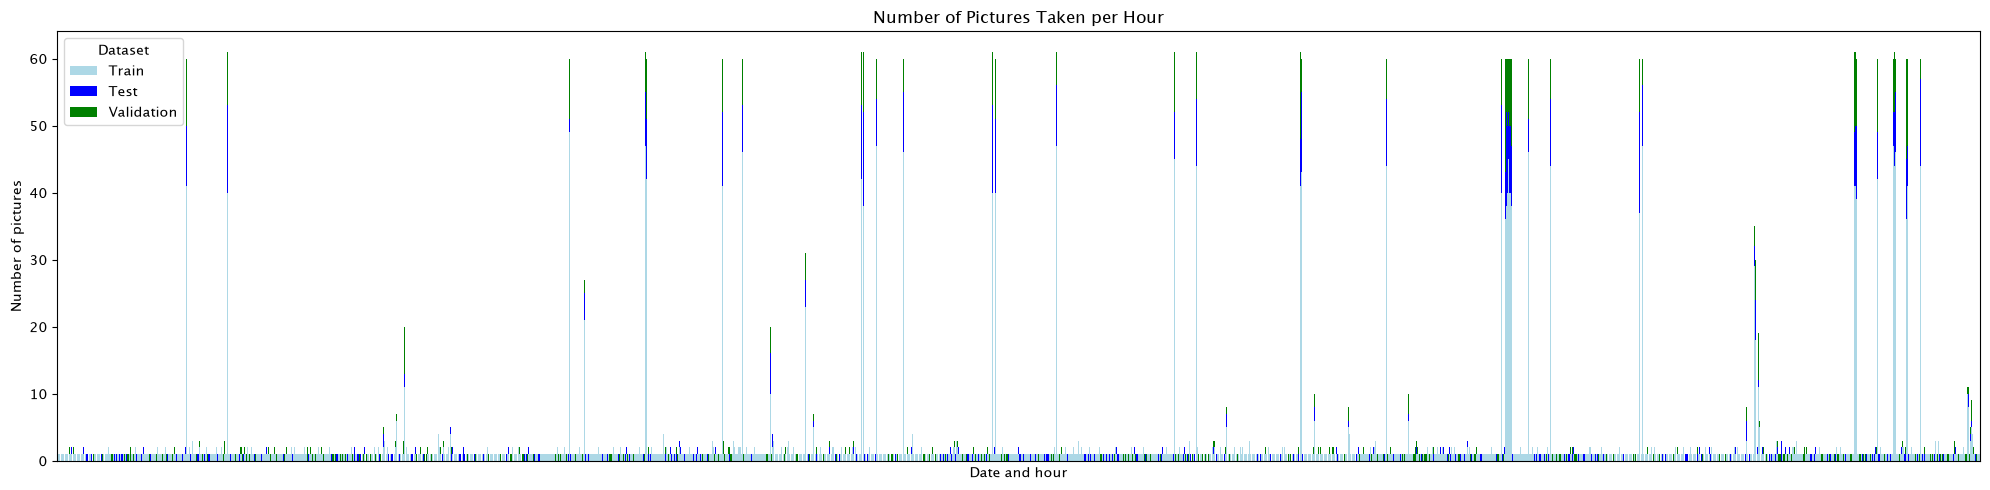

In [43]:
train_hourly_counts = train_set.groupby(
    train_set['datetime'].dt.floor('h')
).size()

test_hourly_counts = test_set.groupby(
    test_set['datetime'].dt.floor('h')
).size()

val_hourly_counts = val_set.groupby(
    val_set['datetime'].dt.floor('h')
).size()

# Align all counts to the same datetime index
hourly_counts = pd.concat(
    [
        train_hourly_counts.rename('Train'),
        test_hourly_counts.rename('Test'),
        val_hourly_counts.rename('Validation')
    ],
    axis=1
).fillna(0)

# Plot stacked bars
ax = hourly_counts.plot(
    kind='bar',
    stacked=True,
    figsize=(20, 5),
    color=['lightblue', 'blue', 'green'],
    width=0.9
)

ax.set_xlabel('Date and hour')
ax.set_ylabel('Number of pictures')
ax.set_title('Number of Pictures Taken per Hour')
ax.legend(title='Dataset')

ax.set_xticks([])

plt.tight_layout()
plt.show()


In [44]:
print(f'Train set size: {len(train_set)}')
print(f'Test set size: {len(test_set)}')
print(f'Validation set size: {len(val_set)}')

print(f'{len(train_set[train_set['aurora'] == 1])/len(train_set)*100:.2f}% of train set images contain Aurora')
print(f'{len(test_set[test_set['aurora'] == 1])/len(test_set)*100:.2f}% of test set images contain Aurora')
print(f'{len(val_set[val_set['aurora'] == 1])/len(val_set)*100:.2f}% ofvalidation set images contain Aurora')

Train set size: 4304
Test set size: 923
Validation set size: 922
53.58% of train set images contain Aurora
52.22% of test set images contain Aurora
52.49% ofvalidation set images contain Aurora


## Making a proper Dataset

In [45]:
class AuroraDataset(Dataset):
    def __init__(self, df, img_size, transform=None):
        super().__init__()

        self.aurora = df['aurora'].to_numpy(dtype=np.float32)
        self.images = []


        for img in df['img']:
            image = (
                    Image.open(img)
                    .convert("RGB")
                    .resize((img_size, img_size), Image.LANCZOS)
            )
            if transform:
                image = transform(image)

            self.images.append((
                np.array(image, dtype=np.float32) # / np.float32(255.0)
            ))

    def __len__(self):
        return len(self.aurora)

    def __getitem__(self, idx):
        return {'img': self.images[idx], 'aurora': self.aurora[idx]}


In [46]:
test_transforms = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomVerticalFlip(),
    v2.RandomRotation(degrees=[0, 270]),
    v2.ColorJitter(
        contrast=0.2,
        saturation=0.3
    ),    
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.GaussianNoise(
        mean=0,
        sigma=0.04
    )
])
val_test_transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

In [47]:
train_dataset = AuroraDataset(train_set, transform=test_transforms, img_size=img_size)
test_dataset = AuroraDataset(test_set, transform=val_test_transforms, img_size=img_size)
val_dataset = AuroraDataset(val_set, transform=val_test_transforms, img_size=img_size)

/var/folders/_9/4gj_fgsn3d76fvs6x3f21kwm0000gn/T/ipykernel_26241/2267610730.py:19: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  np.array(image, dtype=np.float32) # / np.float32(255.0)


## And finally loading it into a DataLoader

In [48]:
train_dataloader = DataLoader(train_dataset, shuffle=True, batch_size=batch_size, drop_last=True)
test_dataloader = DataLoader(test_dataset, shuffle=True, batch_size=batch_size, drop_last=True)
val_dataloader = DataLoader(val_dataset, shuffle=True, batch_size=batch_size, drop_last=True)

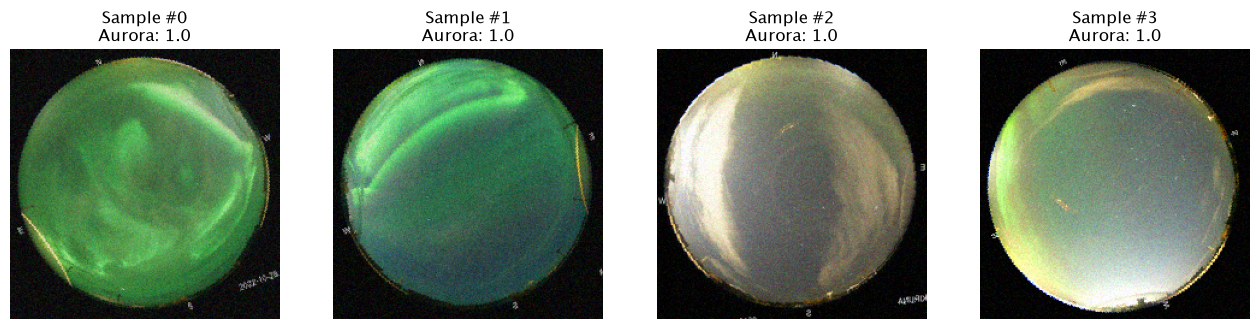

In [49]:
fig = plt.figure(figsize=(16, 5))

first_batch = next(iter(train_dataloader))

for i in range(4):
    ax = plt.subplot(1, 4, i + 1)

    image = first_batch['img'][i].permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(f'Sample #{i}\nAurora: {first_batch['aurora'][i]}')
    ax.axis('off')

# Model

In [72]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # 224
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=9, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # 107

            # 108
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # 53

            # 54
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # 26

            # 26
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=5, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(2),
            # 10
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [73]:
# class CNN(nn.Module):
#     def __init__(self):
#         super().__init__()
#         # Assuming the image is 224x224px
#         # 3 x 224 x 224 (3RGB channels + the image resolution) -> in_channels: 3
#         self.conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5)
#         # out_channels: 6 + kernel_size: 5 -> 224 - 5 + 1 -> 6 x 220 x 220
#         # pooling cuts it down in half: 6 x 110 x 110

#         # 6 x 110 x 110
#         self.conv2 = nn.Conv2d(in_channels=6, out_channels=12, kernel_size=3)
#         # 110 - 3 + 1 -> 12 x 108 x 108
        
#         # 12 x 54 x 54
#         self.conv3 = nn.Conv2d(in_channels=12, out_channels=24, kernel_size=3)
#         # 54 - 3 + 1 -> 24 x 52 x 52

#         # 24 x 26 x 26
#         self.conv4 = nn.Conv2d(in_channels=24, out_channels=48, kernel_size=7)
#         # 26 - 7 + 1 -> 48 x 20 x 20

#         # 48 x 10 x 10

#         self.pool = nn.MaxPool2d(2, 2)

#         self.fc1 = nn.Linear(48*10*10, 3000)
#         self.fc2 = nn.Linear(3000, 500)
#         self.fc3 = nn.Linear(500, 120)
#         self.fc4 = nn.Linear(120, 20)
#         self.fc5 = nn.Linear(20, 1)

#     def forward(self, x):
#         x = self.pool(F.relu(self.conv1(x)))
#         x = self.pool(F.relu(self.conv2(x)))
#         x = self.pool(F.relu(self.conv3(x)))
#         x = self.pool(F.relu(self.conv4(x)))

#         x = torch.flatten(x, 1) # flatten all dimensions except batch
        
#         x = F.relu(self.fc1(x))
#         x = F.relu(self.fc2(x))
#         x = F.relu(self.fc3(x))
#         x = F.relu(self.fc4(x))

#         x = self.fc5(x)

#         return x

In [74]:
# # Using a pretrained Resnet18 model

# net = models.resnet18(weights=ResNet18_Weights.DEFAULT)
# num_features = net.fc.in_features

# net.fc = nn.Linear(num_features, 1)
# net = net.to(device)

In [75]:
net = CNN().to(device)
print(device)

mps


In [76]:
learning_rate = 3e-4 #9e-7

loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    net.parameters(),
    lr=learning_rate,
    weight_decay=1e-5
)

# Training/Validating/Testing

In [77]:
def train_loop(dataloader, model, loss_fn, optimizer):
    num_batches = len(dataloader)

    model.train()

    train_loss = 0
    correct = 0
    total = 0

    for data in dataloader:
        X = data['img'].to(device)
        y = data['aurora'].to(device).float()

        optimizer.zero_grad()

        pred = model(X).squeeze(1)

        loss = loss_fn(pred, y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        predicted = torch.sigmoid(pred) >= 0.5

        correct += (predicted == y.bool()).sum().item()
        total += y.numel()

    train_loss /= num_batches
    accuracy = correct / total

    return train_loss, accuracy


In [78]:
def val_loop(dataloader, model, loss_fn):
    num_batches = len(dataloader)

    model.eval()

    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for data in dataloader:
            X = data['img'].to(device)
            y = data['aurora'].to(device).float()

            pred = model(X).squeeze(1)

            val_loss += loss_fn(pred, y).item()

            predicted = torch.sigmoid(pred) >= 0.5

            correct += (predicted == y.bool()).sum().item()
            total += y.numel()

    val_loss /= num_batches
    accuracy = correct / total

    return val_loss, accuracy


In [79]:
def test_loop(dataloader, model):
    y_test = []
    predictions = []

    model.eval()

    with torch.no_grad():
        for data in dataloader:
            X = data['img'].to(device, non_blocking=True)
            y = data['aurora'].to(device, non_blocking=True).float()
            y_test.extend(y.cpu().numpy().squeeze().astype(int))

            pred = model(X).squeeze(1)

            predicted = torch.sigmoid(pred) >= 0.5
            predictions.extend(predicted.cpu().numpy().squeeze().astype(int))

    cm = confusion_matrix(y_test, predictions)
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    F1 = f1_score(y_test, predictions)

    return cm, accuracy, precision, recall, F1


In [80]:
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_loss = 999999
paitenence = 25
epochs_no_improvement = 0
best_model = net
best_epoch = 0

epochs = 100

for i in range(epochs):
    print(f'\nEpoch: {i + 1}')


    train_loss, train_accuracy = train_loop(
        train_dataloader, net, loss_fn, optimizer
    )

    val_loss, val_accuracy = val_loop(
        val_dataloader, net, loss_fn
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(f"Train loss: {train_loss:.4f}\tTrain accuracy: {train_accuracy*100:.2f}%")
    print(f"Validation loss: {val_loss:.4f}\tValidation accuracy: {val_accuracy*100:.2f}%")

    if(val_loss <= best_loss):
        epochs_no_improvement = 0
        best_epoch = i
        best_loss = val_loss
        best_model_state = copy.deepcopy(net.state_dict())

    else:
        epochs_no_improvement += 1
        if(epochs_no_improvement >= paitenence):
            print(f'Stopped early, no improvement in validation loss for the past {paitenence} epochs')
            epochs = i + 1
            break

print("Done!")
net.load_state_dict(best_model_state)


Epoch: 1
Train loss: 0.6245	Train accuracy: 62.20%
Validation loss: 0.3800	Validation accuracy: 84.93%

Epoch: 2
Train loss: 0.4770	Train accuracy: 78.06%
Validation loss: 0.4385	Validation accuracy: 80.69%

Epoch: 3
Train loss: 0.3792	Train accuracy: 84.56%
Validation loss: 0.2978	Validation accuracy: 87.50%

Epoch: 4
Train loss: 0.3512	Train accuracy: 85.19%
Validation loss: 0.3973	Validation accuracy: 81.25%

Epoch: 5
Train loss: 0.3352	Train accuracy: 85.24%
Validation loss: 0.3683	Validation accuracy: 81.14%

Epoch: 6
Train loss: 0.3117	Train accuracy: 87.20%
Validation loss: 0.2470	Validation accuracy: 90.96%

Epoch: 7
Train loss: 0.3049	Train accuracy: 87.66%
Validation loss: 0.2899	Validation accuracy: 86.83%

Epoch: 8
Train loss: 0.2763	Train accuracy: 88.64%
Validation loss: 0.2418	Validation accuracy: 90.29%

Epoch: 9
Train loss: 0.2747	Train accuracy: 89.09%
Validation loss: 0.2424	Validation accuracy: 90.18%

Epoch: 10
Train loss: 0.2814	Train accuracy: 88.25%
Validation 

<All keys matched successfully>

Accuracy: 95.20%
Precision: 96.92%
Recall: 93.82%
F1: 95.34%


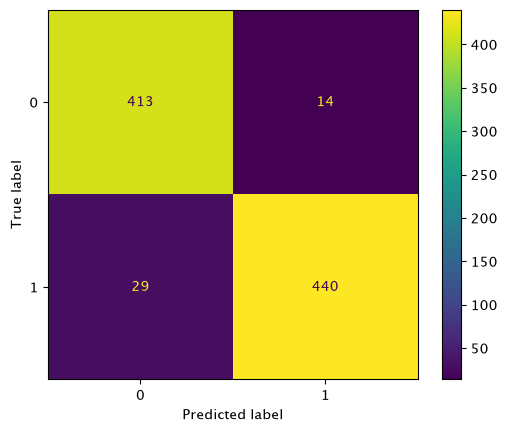

In [81]:
cm, accuracy, precision, recall, F1 = test_loop(test_dataloader, net)

print(f'Accuracy: {accuracy * 100:.2f}%')
print(f'Precision: {precision * 100:.2f}%')
print(f'Recall: {recall * 100:.2f}%')
print(f'F1: {F1 * 100:.2f}%')
ConfusionMatrixDisplay(cm).plot()


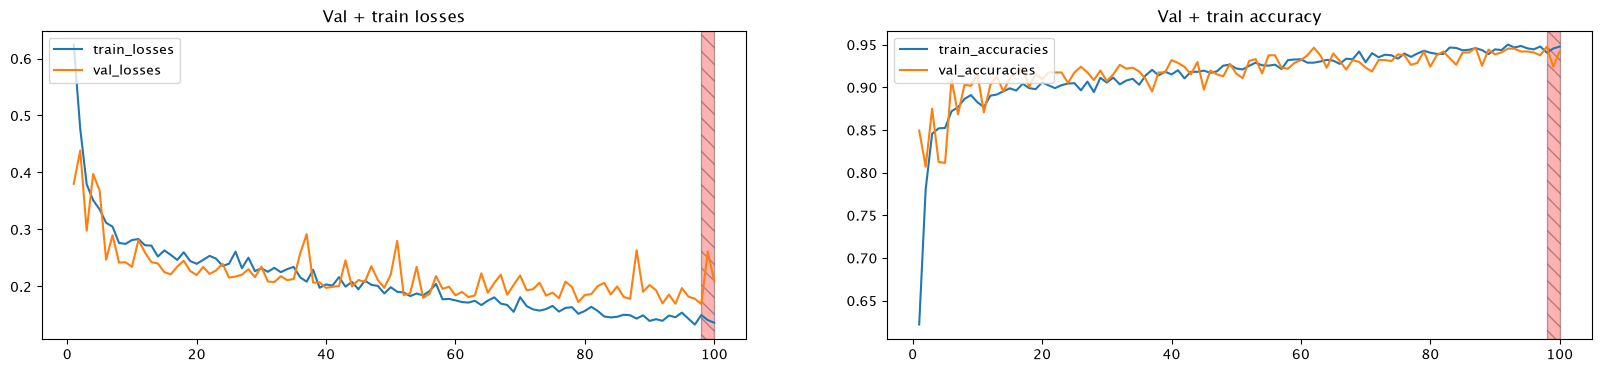

In [82]:
epoch_range = range(1, epochs + 1)

plt.figure(figsize=(20, 4))

plt.subplot(1, 2, 1)
plt.title('Val + train losses')
plt.plot(epoch_range, train_losses, label="train_losses")
plt.plot(epoch_range, val_losses, label="val_losses")
plt.axvspan(best_epoch + 1, epochs, facecolor='red', alpha=0.3, hatch='\\\\', edgecolor='black')
plt.legend(loc="upper left")

plt.subplot(1, 2, 2)
plt.title('Val + train accuracy')
plt.plot(epoch_range, train_accuracies, label="train_accuracies")
plt.plot(epoch_range, val_accuracies, label="val_accuracies")
plt.axvspan(best_epoch + 1, epochs, facecolor='red', alpha=0.3, hatch='\\\\', edgecolor='black')
plt.legend(loc="upper left")

plt.show()

In [83]:
def predict_image(path, model, threshold=0.5):
    model.eval()

    image = (
        Image.open(path)
        .convert("RGB")
        .resize((img_size, img_size), Image.LANCZOS)
    )
    image_np = np.array(image, dtype=np.float32) / 255.0

    image_tensor = (
        torch.from_numpy(image_np)
        .permute(2, 0, 1)
        .unsqueeze(0)
        .to(device)
    )

    with torch.no_grad():
        logits = model(image_tensor)
        probabilities = torch.sigmoid(logits)[0]

    predictions = probabilities >= threshold

    plt.figure(figsize=(8, 6))
    plt.imshow(image)
    plt.axis("off")

    title = "\n".join(
        f"{label}: {probability:.1%} "
        f"{'✓' if prediction else '✗'}"
        for label, probability, prediction
        in zip(labels, probabilities, predictions)
    )

    plt.title(title)
    plt.show()

In [84]:
torch.save(net, 'model.pt')

/Users/petarbabic/Library/Mobile Documents/com~apple~CloudDocs/Faks/SpaceMaster/Aalto/Projects/Machine Learning/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Lucida Grande.
  fig.canvas.print_figure(bytes_io, **kw)


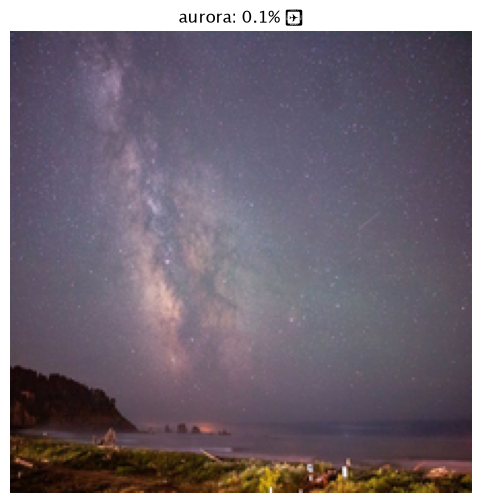

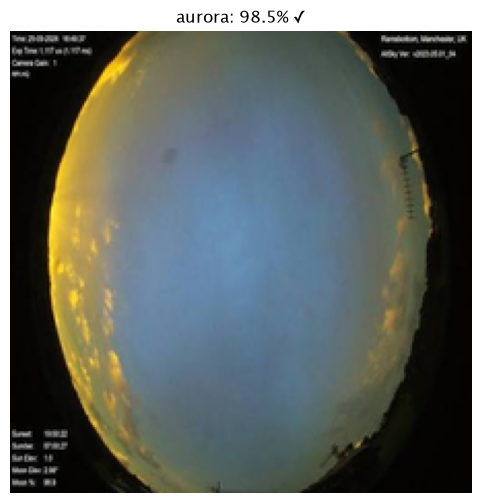

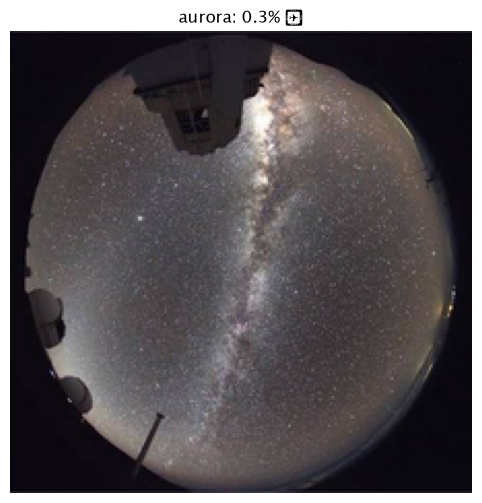

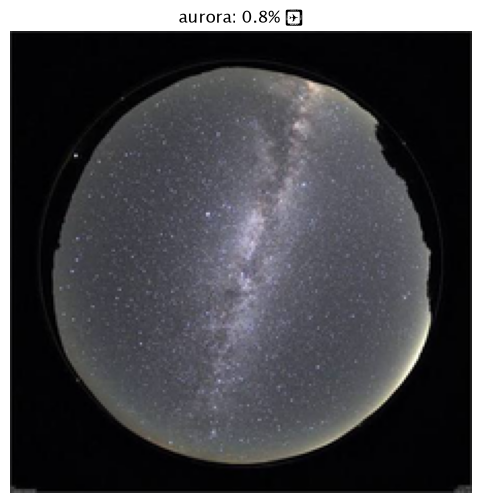

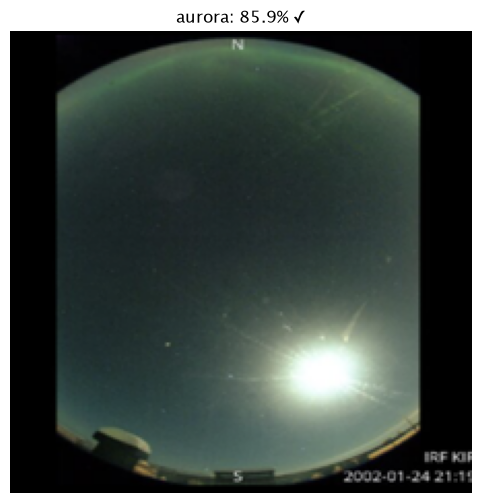

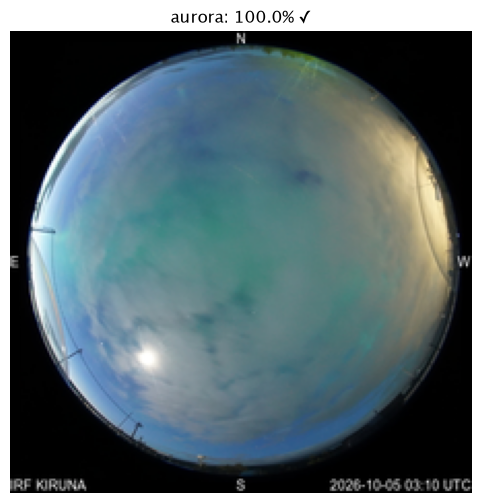

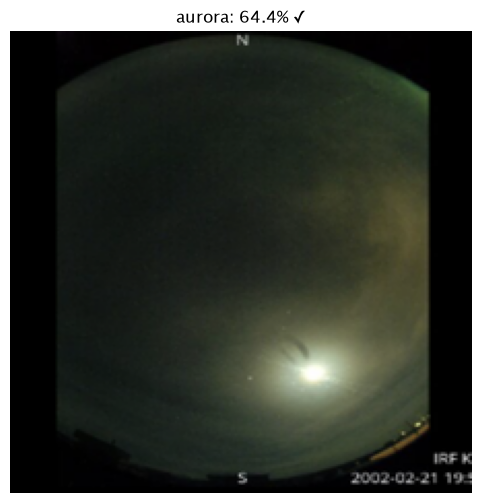

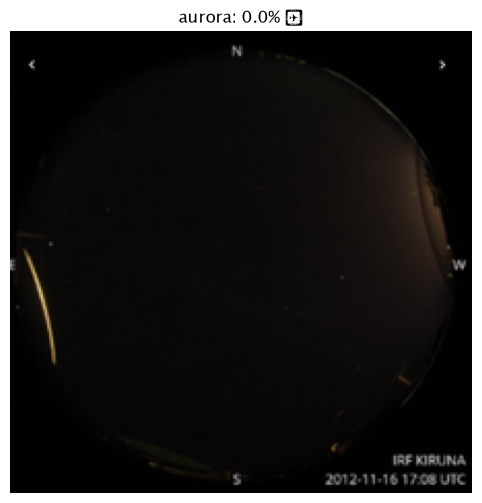

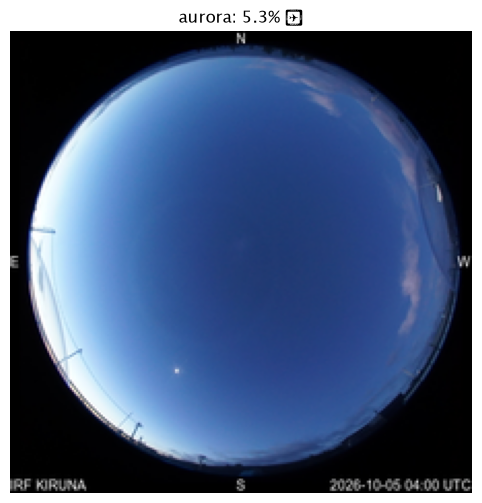

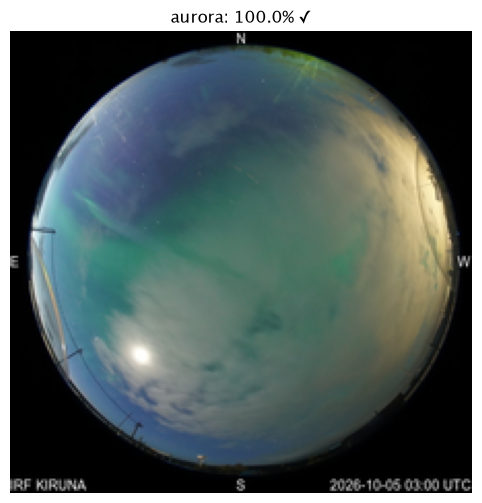

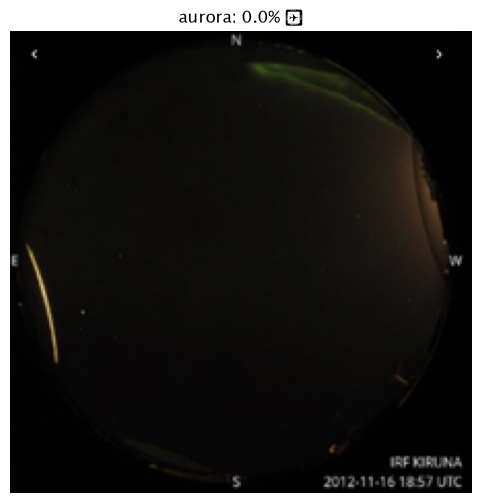

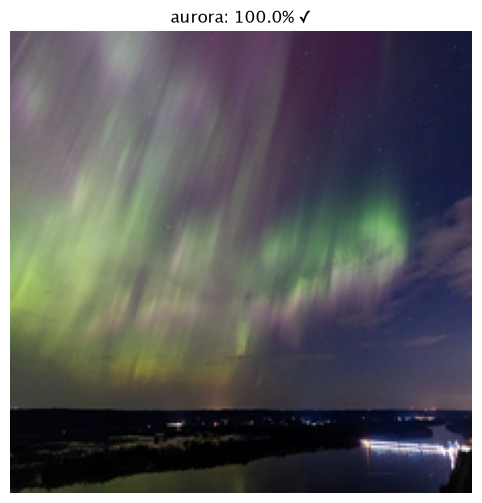

In [85]:
for file in os.listdir("Unseen data"):
    predict_image('Unseen data/' + file, net)